In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment ready!")

Environment ready!


# Week 2 - Baseline Models and Evaluation

**Project:** Predicting Term Deposit Subscription

**Author:** Mariem Dridi

## 1. Objective

The objective of this notebook is to implement and evaluate
two baseline models: a Dummy Classifier and Logistic Regression.

We reuse the cleaned dataset and preprocessing functions
developed in the previous module.

All models are fitted on the training set and evaluated on
the validation set. The test set is reserved for final evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

from src.data_prep import split, build_preprocessor

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading

We use the cleaned dataset containing 41,176 observations.

The cleaning process has already removed exact duplicates,
excluded the duration feature to prevent data leakage,
and encoded the target variable as 0 and 1.

No additional cleaning is performed in this notebook.

In [3]:
df = pd.read_csv("bank_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (41176, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'was_contacted_before']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,was_contacted_before
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [4]:
assert len(df) == 41176, "Unexpected number of rows"
assert df.shape[1] == 21, "Unexpected number of columns"
assert "duration" not in df.columns, "Data leakage detected"
assert set(df["y"].unique()) == {0, 1}, "Invalid target encoding"
assert df.isna().sum().sum() == 0, "Missing values detected"

print("All data checks passed.")

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget distribution (%):")
print(df["y"].value_counts(normalize=True) * 100)

All data checks passed.

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Target distribution (%):
y
0    88.733728
1    11.266272
Name: proportion, dtype: float64


The dataset is highly imbalanced, with 88.73% of observations
belonging to the negative class and only 11.27% to the positive
class.

A model that always predicts no subscription could achieve
approximately 88.73% accuracy without identifying any actual
subscribers. Therefore, accuracy alone is not sufficient to
evaluate model performance.

We will focus on Average Precision, recall, precision,
F1-score and ROC-AUC.

## 3. Train, Validation and Test Split

We reuse the stratified splitting function from the
preprocessing module with random_state=42.

- Training set (60%): model fitting.
- Validation set (20%): model evaluation and threshold selection.
- Test set (20%): final evaluation only.

Stratification preserves the target class proportions
across the three subsets.

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = split(df)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

assert len(X_train) == 24705
assert len(X_val) == 8235
assert len(X_test) == 8236

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nSplit checks passed.")

Training set: (24705, 20)
Validation set: (8235, 20)
Test set: (8236, 20)

Split checks passed.


In [6]:
split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100
})

split_summary.round(2)

,Training,Validation
y,,
0,88.74,88.73
1,11.26,11.27


## 4. Dummy Classifier

The Dummy Classifier is used as a reference baseline.

With strategy="prior", it always predicts the majority class
and returns probabilities based on the training class distribution.

This baseline illustrates why accuracy alone is misleading
when dealing with imbalanced classification problems.

In [7]:
dummy_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", DummyClassifier(strategy="prior"))
])

dummy_pipeline.fit(X_train, y_train)

print("Dummy Classifier trained successfully.")

Dummy Classifier trained successfully.


In [8]:
dummy_pred = dummy_pipeline.predict(X_val)

dummy_proba = dummy_pipeline.predict_proba(X_val)[:, 1]

print("Predicted class distribution:")
print(pd.Series(dummy_pred).value_counts())

print("\nFirst 5 predicted probabilities:")
print(dummy_proba[:5])

Predicted class distribution:
0    8235
Name: count, dtype: int64

First 5 predicted probabilities:
[0.11264926 0.11264926 0.11264926 0.11264926 0.11264926]


In [9]:
dummy_results = {
    "Accuracy": accuracy_score(y_val, dummy_pred),
    "Precision": precision_score(y_val, dummy_pred, zero_division=0),
    "Recall": recall_score(y_val, dummy_pred, zero_division=0),
    "F1-score": f1_score(y_val, dummy_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, dummy_proba),
    "Average Precision": average_precision_score(y_val, dummy_proba)
}

pd.DataFrame([dummy_results], index=["Dummy Classifier"]).round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0,0.0,0.0,0.5,0.1127


## 5. Logistic Regression

Logistic Regression is selected as our main baseline
because it is simple, interpretable and computationally
efficient for binary classification.

The model estimates the probability of a customer
subscribing to a term deposit.

We use the default regularization settings without
class weighting or resampling to establish a standard
baseline for future experiments.

The preprocessing and classification steps are combined
in a single pipeline fitted exclusively on the training set.

In [10]:
lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [11]:
lr_pred = lr_pipeline.predict(X_val)

lr_proba = lr_pipeline.predict_proba(X_val)[:, 1]

print("Predicted class distribution:")
print(pd.Series(lr_pred).value_counts())

print("\nFirst 5 predicted probabilities:")
print(lr_proba[:5])

Predicted class distribution:
0    7939
1     296
Name: count, dtype: int64

First 5 predicted probabilities:
[0.03707723 0.05124307 0.05016525 0.03620515 0.02008626]


In [12]:
lr_results = {
    "Accuracy": accuracy_score(y_val, lr_pred),
    "Precision": precision_score(y_val, lr_pred, zero_division=0),
    "Recall": recall_score(y_val, lr_pred, zero_division=0),
    "F1-score": f1_score(y_val, lr_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, lr_proba),
    "Average Precision": average_precision_score(y_val, lr_proba)
}

pd.DataFrame(
    [lr_results],
    index=["Logistic Regression"]
).round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Logistic Regression,0.9012,0.6926,0.2209,0.335,0.8081,0.4742


## 6. Baseline Model Comparison

We compare the Dummy Classifier and Logistic Regression
on the same validation set using six evaluation metrics.

Due to class imbalance, we pay particular attention to
Average Precision, recall, F1-score and ROC-AUC.

In [13]:
comparison = pd.DataFrame(
    [dummy_results, lr_results],
    index=["Dummy Classifier", "Logistic Regression"]
)

comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0000,0.0000,0.000,0.5000,0.1127
Logistic Regression,0.9012,0.6926,0.2209,0.335,0.8081,0.4742


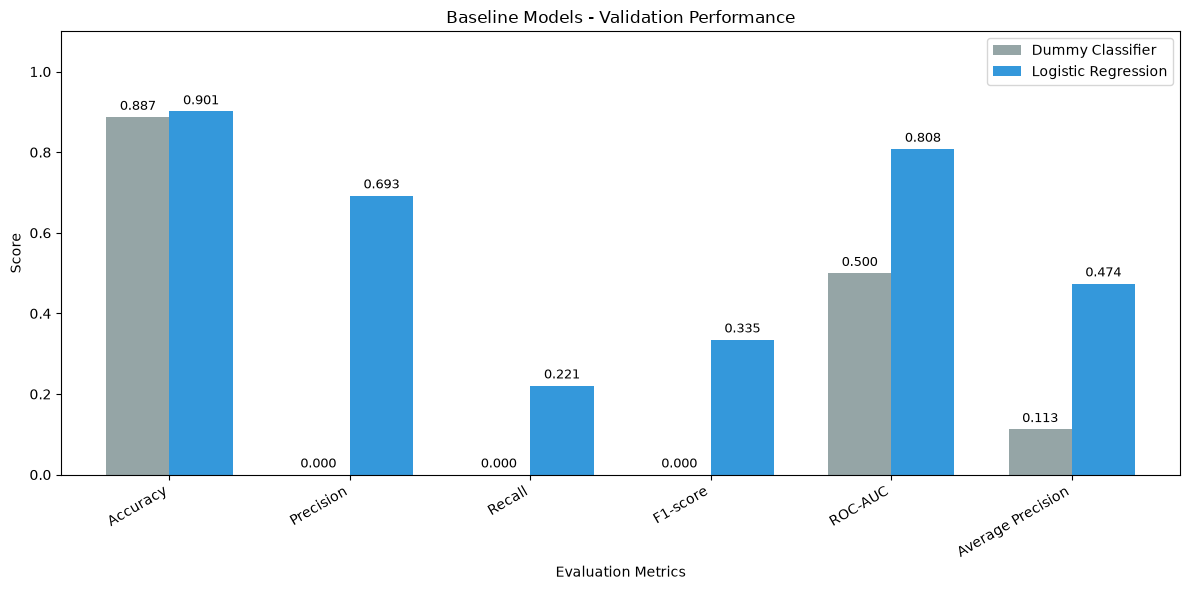

In [14]:
ax = comparison.T.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#95A5A6", "#3498DB"],
    width=0.7
)

plt.title("Baseline Models - Validation Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="upper right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

### Model Comparison and Interpretation

Logistic Regression outperforms the Dummy Classifier
across all evaluation metrics.

The ROC-AUC of 0.8081 indicates good discrimination
ability, while Average Precision increases from
0.1127 to 0.4742.

However, despite a precision of 69.26%, the model
achieves a recall of only 22.09%, missing approximately
78% of actual subscribers.

This limitation is particularly important in bank
marketing, where missing potential subscribers may
represent lost business opportunities.

Threshold optimization will be explored to improve
the balance between precision and recall.

## 7. Confusion Matrices

Confusion matrices provide a detailed analysis of
correct and incorrect predictions for both models.

They help identify false positives and false negatives,
which are particularly important in bank marketing.

In [15]:
dummy_cm = confusion_matrix(y_val, dummy_pred)
lr_cm = confusion_matrix(y_val, lr_pred)

print("Dummy Classifier:")
print(dummy_cm)

print("\nLogistic Regression:")
print(lr_cm)

Dummy Classifier:
[[7307    0]
 [ 928    0]]

Logistic Regression:
[[7216   91]
 [ 723  205]]


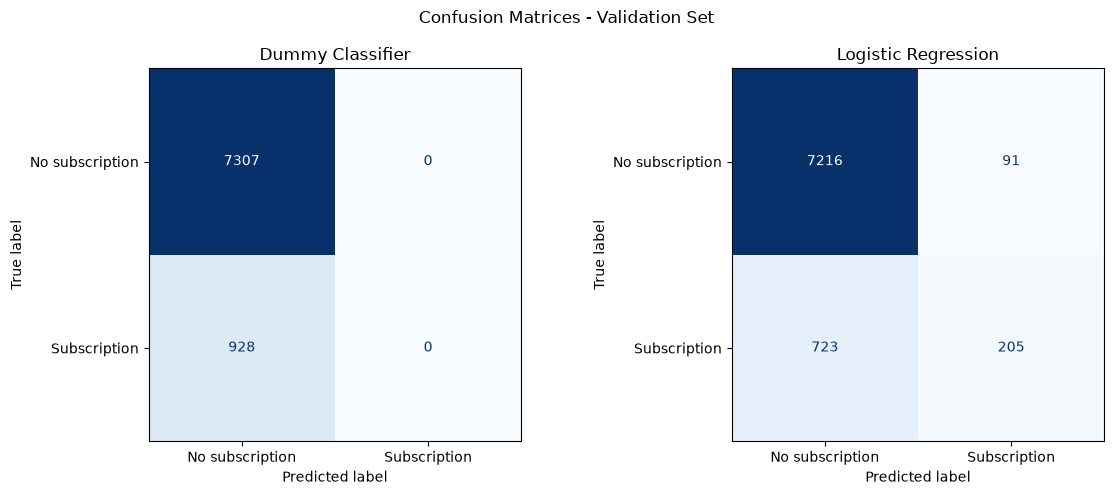

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=dummy_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Dummy Classifier")

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title("Logistic Regression")

plt.suptitle("Confusion Matrices - Validation Set")
plt.tight_layout()
plt.show()

## 8. ROC and Precision-Recall Curves

The ROC curve evaluates the model's ability to distinguish
between subscribers and non-subscribers across different
decision thresholds.

The Precision-Recall curve evaluates the trade-off between
precision and recall.

The Precision-Recall curve is particularly relevant
for our dataset because the positive class is underrepresented.

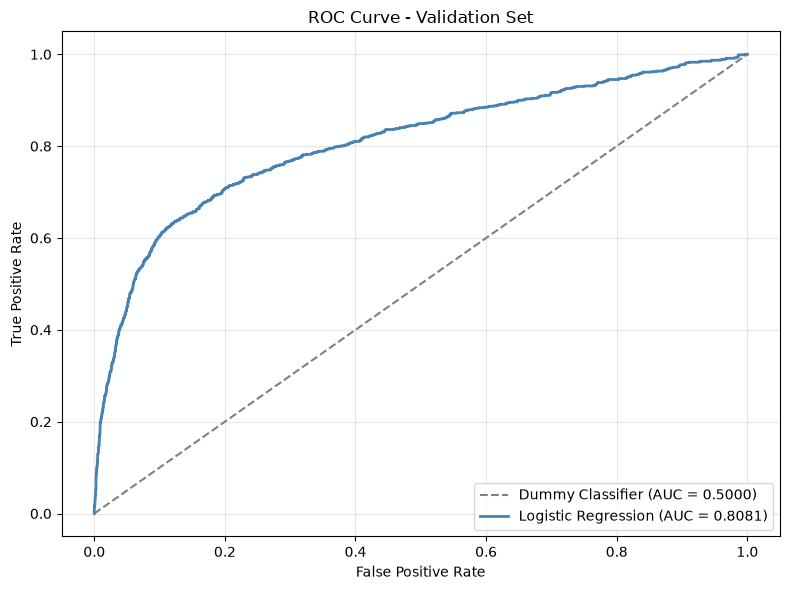

In [17]:
dummy_fpr, dummy_tpr, _ = roc_curve(y_val, dummy_proba)
lr_fpr, lr_tpr, _ = roc_curve(y_val, lr_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    dummy_fpr, dummy_tpr,
    linestyle="--",
    color="gray",
    label=f"Dummy Classifier (AUC = {dummy_results['ROC-AUC']:.4f})"
)

plt.plot(
    lr_fpr, lr_tpr,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_results['ROC-AUC']:.4f})"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

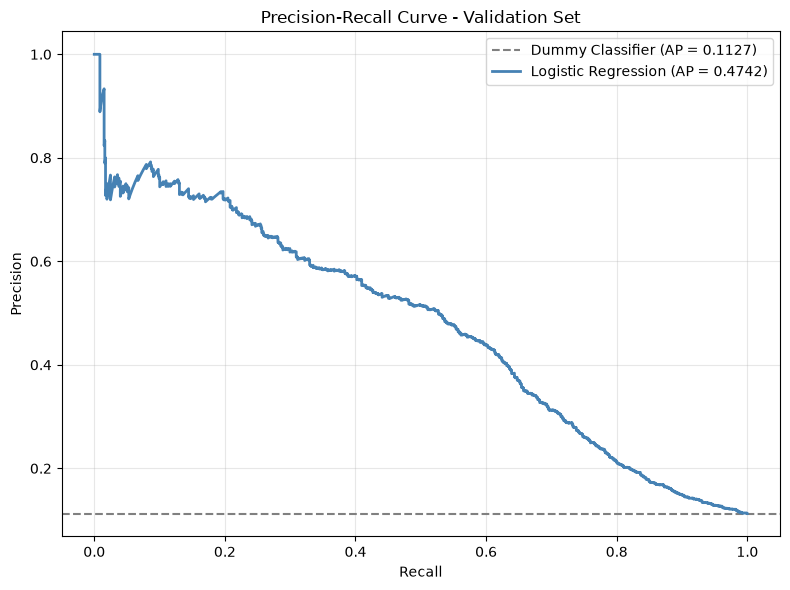

In [18]:
lr_precision, lr_recall, lr_thresholds = precision_recall_curve(
    y_val, lr_proba
)

baseline_ap = y_val.mean()

plt.figure(figsize=(8, 6))

plt.axhline(
    y=baseline_ap,
    color="gray",
    linestyle="--",
    label=f"Dummy Classifier (AP = {baseline_ap:.4f})"
)

plt.plot(
    lr_recall, lr_precision,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AP = {lr_results['Average Precision']:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Decision Threshold Optimization

The default classification threshold of 0.5 results
in a low recall of 22.09%.

To improve the detection of potential subscribers,
we investigate alternative decision thresholds.

The optimal threshold is selected by maximizing the
F1-score on the validation set.

This approach balances precision and recall without
retraining the model.

The test set remains untouched to prevent data leakage
and preserve an independent final evaluation.

In [19]:
precision, recall, thresholds = precision_recall_curve(
    y_val, lr_proba
)

# Compute F1-score for each threshold
f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(precision[:-1]),
    where=(precision[:-1] + recall[:-1]) != 0
)

# Find the threshold with the highest F1-score
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Default threshold: 0.5000")
print(f"Optimal threshold: {best_threshold:.4f}")
print(f"Best F1-score: {best_f1:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")

Default threshold: 0.5000
Optimal threshold: 0.2385
Best F1-score: 0.5156
Precision: 0.5046
Recall: 0.5269


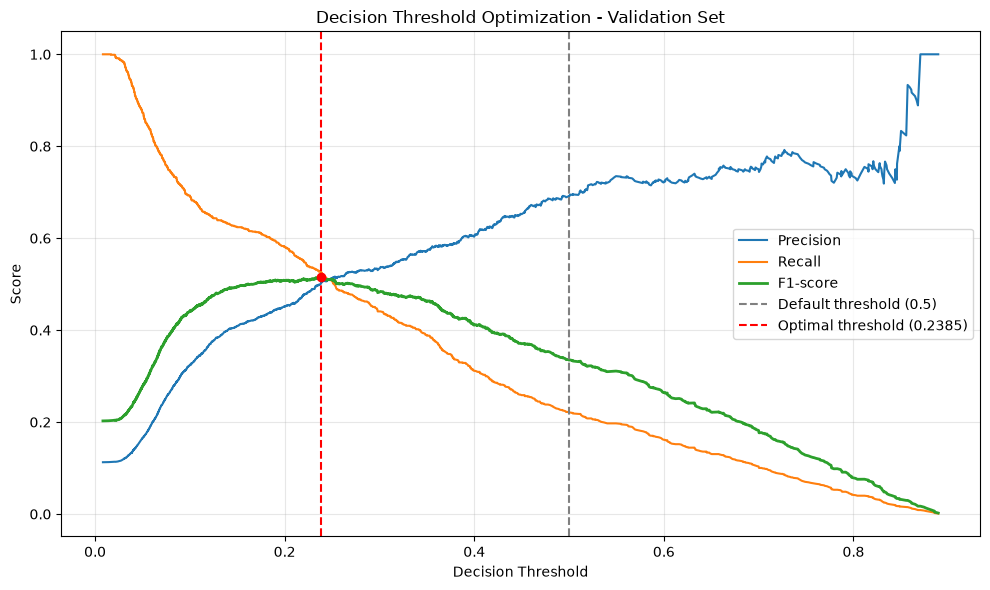

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score", linewidth=2)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Optimal threshold ({best_threshold:.4f})"
)

plt.scatter(best_threshold, best_f1, color="red", zorder=5)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Decision Threshold Optimization - Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
lr_optimized_pred = (lr_proba >= best_threshold).astype(int)

lr_optimized_results = {
    "Accuracy": accuracy_score(y_val, lr_optimized_pred),
    "Precision": precision_score(
        y_val, lr_optimized_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, lr_optimized_pred),
    "F1-score": f1_score(y_val, lr_optimized_pred),
    "ROC-AUC": roc_auc_score(y_val, lr_proba),
    "Average Precision": average_precision_score(y_val, lr_proba)
}

threshold_comparison = pd.DataFrame(
    [lr_results, lr_optimized_results],
    index=["Default Threshold", "Optimized Threshold"]
)

threshold_comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Default Threshold,0.9012,0.6926,0.2209,0.3350,0.8081,0.4742
Optimized Threshold,0.8884,0.5046,0.5269,0.5156,0.8081,0.4742


In [22]:
lr_optimized_cm = confusion_matrix(
    y_val, lr_optimized_pred
)

print("Default threshold (0.5):")
print(lr_cm)

print(f"\nOptimized threshold ({best_threshold:.4f}):")
print(lr_optimized_cm)

Default threshold (0.5):
[[7216   91]
 [ 723  205]]

Optimized threshold (0.2385):
[[6827  480]
 [ 439  489]]


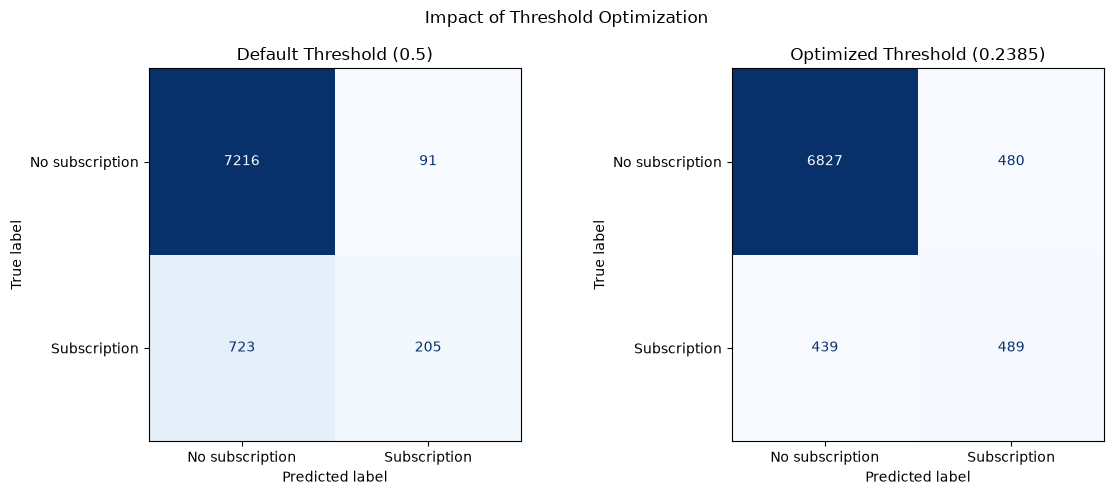

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Default Threshold (0.5)")

ConfusionMatrixDisplay(
    confusion_matrix=lr_optimized_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title(
    f"Optimized Threshold ({best_threshold:.4f})"
)

plt.suptitle("Impact of Threshold Optimization")
plt.tight_layout()
plt.show()

## 10. Final Baseline Performance Summary

In [24]:
final_comparison = pd.DataFrame(
    [
        dummy_results,
        lr_results,
        lr_optimized_results
    ],
    index=[
        "Dummy Classifier",
        "Logistic Regression (Default)",
        "Logistic Regression (Optimized)"
    ]
)

final_comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0000,0.0000,0.0000,0.5000,0.1127
Logistic Regression (Default),0.9012,0.6926,0.2209,0.3350,0.8081,0.4742
Logistic Regression (Optimized),0.8884,0.5046,0.5269,0.5156,0.8081,0.4742


## 11. Conclusion

### Main Findings

The Dummy Classifier demonstrates that accuracy alone
is misleading for our imbalanced dataset.

Logistic Regression provides a stronger baseline,
achieving a ROC-AUC of 0.8081 and an Average Precision
of 0.4742.

Optimizing the decision threshold to 0.2385 improves
recall from 22.09% to 52.69% and F1-score from 0.3350
to 0.5156.

The optimized Logistic Regression is therefore selected
as our reference baseline for future model comparisons
when prioritizing F1-score.

### Limitations

- The dataset is highly imbalanced, with only 11.27%
  positive observations.
- Identical feature vectors remaining after the removal
  of duration may lead to optimistic performance estimates.
- Threshold optimization and evaluation use the same
  validation set.
- The optimal business threshold cannot be determined
  without information about contact costs and subscription
  benefits.
- Probability calibration has not yet been assessed.

### Recommendations for Future Work

- Compare Logistic Regression with more advanced models,
  such as Random Forest and Gradient Boosting.
- Investigate class weighting and resampling techniques.
- Evaluate probability calibration.
- Use Average Precision and F1-score as key comparison
  metrics alongside precision, recall and ROC-AUC.
- Evaluate the final selected model on the independent
  test set only after model and threshold selection.

The test set has not been used during this baseline
development phase.

## Appendix - AI Audit Verification

This section provides experimental evidence supporting
the corrections documented in AI_AUDIT.md.

- Audit 1: Verification of pdays sentinel handling.
- Audit 2: Verification of the shared preprocessing
  function signature.

These checks are independent of model training,
validation and threshold optimization.

In [25]:
import inspect
import pandas as pd
from src.data_prep import build_preprocessor

# Audit 1: Verify sentinel value handling
raw_df = pd.read_csv("bank-additional-full.csv", sep=";")
clean_df = pd.read_csv("bank_clean.csv")

print("=== Audit 1: pdays sentinel ===")
print("Raw pdays=999:", (raw_df["pdays"] == 999).sum())
print("Clean pdays=999:", (clean_df["pdays"] == 999).sum())
print("Contact indicator exists:",
      "was_contacted_before" in clean_df.columns)

# Audit 2: Verify shared function signature
print("\n=== Audit 2: Function signature ===")
print(inspect.signature(build_preprocessor))

try:
    build_preprocessor(X_train)
except TypeError as e:
    print("AI-generated code failed:", e)

preprocessor_check = build_preprocessor()
print("Corrected function call: successful")

=== Audit 1: pdays sentinel ===
Raw pdays=999: 39673
Clean pdays=999: 0
Contact indicator exists: True

=== Audit 2: Function signature ===
()
AI-generated code failed: build_preprocessor() takes 0 positional arguments but 1 was given
Corrected function call: successful


## Temporal Split — Sensitivity Analysis

### Objective

This experiment evaluates the robustness of the baseline models
under a chronological data split.

Unlike the previous stratified random split, the temporal split
preserves the original row order:

- Training set: first 60% of observations.
- Validation set: next 20% of observations.
- Test set: last 20% of observations.

The same baseline models and evaluation metrics are used to
ensure a fair methodological comparison.

The decision threshold is optimized again using only the
temporal validation set.

The test set remains untouched for final evaluation.

This experiment assumes that the cleaned dataset preserves
the original chronological row order.

In [26]:
from src.data_prep import time_split

# Load the shared cleaned dataset
df_temporal = pd.read_csv("bank_clean.csv")

# Chronological split
(
    X_train_time,
    X_val_time,
    _X_test_time,
    y_train_time,
    y_val_time,
    _y_test_time
) = time_split(df_temporal)

# Verify training and validation sizes
assert len(X_train_time) == 24705
assert len(X_val_time) == 8235

# Verify chronological separation
assert X_train_time.index.max() < X_val_time.index.min()

# Verify absence of index overlap
assert set(X_train_time.index).isdisjoint(X_val_time.index)

# Display training and validation distributions
print("Temporal training shape:", X_train_time.shape)
print("Temporal validation shape:", X_val_time.shape)

print("\nTraining target distribution (%):")
print(y_train_time.value_counts(normalize=True).sort_index() * 100)

print("\nValidation target distribution (%):")
print(y_val_time.value_counts(normalize=True).sort_index() * 100)

Temporal training shape: (24705, 20)
Temporal validation shape: (8235, 20)

Training target distribution (%):
y
0    95.191257
1     4.808743
Name: proportion, dtype: float64

Validation target distribution (%):
y
0    88.925319
1    11.074681
Name: proportion, dtype: float64


### Temporal Split Observations

The temporal training set contains only 4.81% positive
observations, compared with 11.07% in the validation set.

Unlike the stratified random split, the chronological split
reveals a substantial change in the target distribution.

This difference may affect the model's ability to identify
subscribers and may lead to lower predictive performance.

The temporal split provides a more realistic evaluation
of the model's ability to generalize to future observations.

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from src.data_prep import build_preprocessor

# Dummy baseline - temporal split
dummy_time = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", DummyClassifier(strategy="prior"))
])

# Logistic Regression - temporal split
logreg_time = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train exclusively on the temporal training set
dummy_time.fit(X_train_time, y_train_time)
logreg_time.fit(X_train_time, y_train_time)

print("Temporal DummyClassifier trained successfully.")
print("Temporal Logistic Regression trained successfully.")

Temporal DummyClassifier trained successfully.
Temporal Logistic Regression trained successfully.


### Temporal Baseline Evaluation

Both models are evaluated exclusively on the temporal
validation set using the same metrics as the random split:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average Precision

The default decision threshold is used before performing
threshold optimization.

No test data is used for evaluation or model selection.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Verify positive-class ordering
assert list(dummy_time.classes_) == [0, 1]
assert list(logreg_time.classes_) == [0, 1]

# Predictions on temporal validation set
y_pred_dummy_time = dummy_time.predict(X_val_time)
y_pred_logreg_time = logreg_time.predict(X_val_time)

# Positive-class probabilities
y_proba_dummy_time = dummy_time.predict_proba(X_val_time)[:, 1]
y_proba_logreg_time = logreg_time.predict_proba(X_val_time)[:, 1]

# Evaluation function
def evaluate_temporal_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Average Precision": average_precision_score(y_true, y_proba)
    }

# Temporal validation results
temporal_results = pd.DataFrame([
    evaluate_temporal_model(
        "DummyClassifier",
        y_val_time,
        y_pred_dummy_time,
        y_proba_dummy_time
    ),
    evaluate_temporal_model(
        "Logistic Regression (0.5)",
        y_val_time,
        y_pred_logreg_time,
        y_proba_logreg_time
    )
])

display(temporal_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,DummyClassifier,0.8893,0.0,0.0,0.0,0.5000,0.1107
1,Logistic Regression (0.5),0.8893,0.0,0.0,0.0,0.4836,0.0984


### Temporal Threshold Optimization

At the default threshold of 0.5, Logistic Regression
fails to identify any positive observations.

The decision threshold is therefore optimized by maximizing
the F1-score on the temporal validation set.

The threshold selected during the random-split experiment
is not reused because the training and validation
distributions have changed.

No test data is used for threshold selection.

In [29]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Compute precision and recall for candidate thresholds
precision_time, recall_time, thresholds_time = (
    precision_recall_curve(y_val_time, y_proba_logreg_time)
)

# Compute F1-score for each threshold
f1_scores_time = np.divide(
    2 * precision_time[:-1] * recall_time[:-1],
    precision_time[:-1] + recall_time[:-1],
    out=np.zeros_like(thresholds_time),
    where=(precision_time[:-1] + recall_time[:-1]) != 0
)

# Select the threshold maximizing validation F1
best_idx_time = np.argmax(f1_scores_time)
best_threshold_time = thresholds_time[best_idx_time]

print(f"Best temporal threshold: {best_threshold_time:.6f}")
print(f"Best temporal F1-score: {f1_scores_time[best_idx_time]:.4f}")

# Apply the optimized threshold
y_pred_optimized_time = (
    y_proba_logreg_time >= best_threshold_time
).astype(int)

# Evaluate optimized model
optimized_time_result = evaluate_temporal_model(
    "Logistic Regression (Optimized)",
    y_val_time,
    y_pred_optimized_time,
    y_proba_logreg_time
)

# Add optimized model to the results table
temporal_results = pd.concat([
    temporal_results.iloc[:2],
    pd.DataFrame([optimized_time_result])
], ignore_index=True)

display(temporal_results.round(4))

Best temporal threshold: 0.000008
Best temporal F1-score: 0.2187


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,DummyClassifier,0.8893,0.0000,0.0000,0.0000,0.5000,0.1107
1,Logistic Regression (0.5),0.8893,0.0000,0.0000,0.0000,0.4836,0.0984
2,Logistic Regression (Optimized),0.3552,0.1263,0.8147,0.2187,0.4836,0.0984


### Temporal Confusion Matrices

The confusion matrices illustrate the impact of threshold
optimization on classification errors.

Lowering the threshold increases the number of correctly
identified subscribers but also generates more false positives.

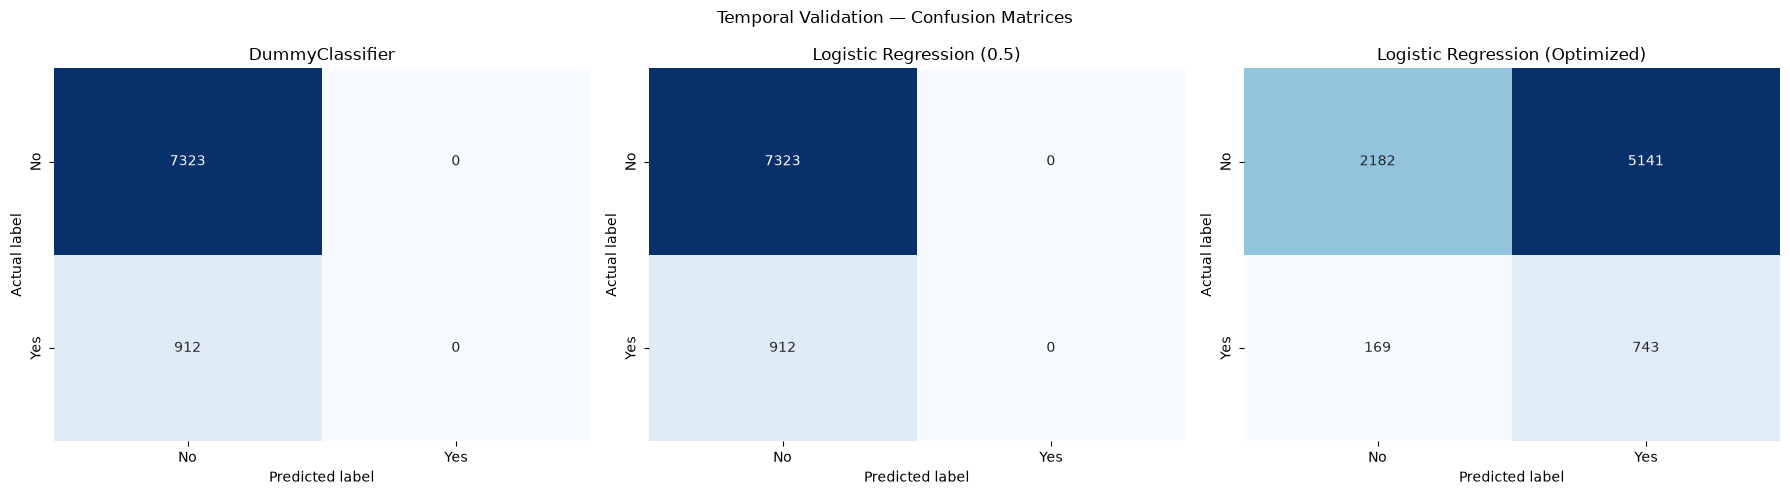

Optimized temporal threshold: 7.796304746164699e-06


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

temporal_predictions = [
    ("DummyClassifier", y_pred_dummy_time),
    ("Logistic Regression (0.5)", y_pred_logreg_time),
    ("Logistic Regression (Optimized)", y_pred_optimized_time)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, temporal_predictions):

    cm = confusion_matrix(
        y_val_time,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.suptitle("Temporal Validation — Confusion Matrices")
plt.tight_layout()
plt.show()

print("Optimized temporal threshold:", best_threshold_time)

### Confusion Matrix Interpretation

At the default threshold, Logistic Regression predicts
all customers as non-subscribers, missing all 912
positive observations.

After threshold optimization, the model correctly
identifies 743 subscribers but generates 5,141 false
positives.

Although recall increases significantly, the large
number of false positives limits the practical usefulness
of the model.

The extremely low optimized threshold also indicates
that the model assigns very low subscription probabilities
to most temporal validation observations.

### Random vs Temporal Split Comparison

The following table compares the validation performance
of the same baseline models under both splitting strategies.

Each optimized threshold is selected independently using
its corresponding validation set.

No test set is used in this comparison.

In [31]:
# Previously obtained random-split validation results
random_comparison = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "Logistic Regression (0.5)",
        "Logistic Regression (Optimized)"
    ],
    "Accuracy": [0.8873, 0.9012, 0.8884],
    "Precision": [0.0000, 0.6926, 0.5046],
    "Recall": [0.0000, 0.2209, 0.5269],
    "F1-score": [0.0000, 0.3350, 0.5156],
    "ROC-AUC": [0.5000, 0.8081, 0.8081],
    "Average Precision": [0.1127, 0.4742, 0.4742]
})

# Compare both splitting strategies side by side
comparison = pd.concat(
    [
        random_comparison.set_index("Model"),
        temporal_results.set_index("Model")
    ],
    axis=1,
    keys=["Random Split", "Temporal Split"]
)

# Group results by metric
comparison = comparison.swaplevel(0, 1, axis=1)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

comparison = comparison.reindex(
    columns=pd.MultiIndex.from_product([
        metrics,
        ["Random Split", "Temporal Split"]
    ])
)

display(comparison.round(4))

Accuracy                   Precision  \
                                Random Split Temporal Split Random Split   
Model                                                                      
DummyClassifier                       0.8873         0.8893       0.0000   
Logistic Regression (0.5)             0.9012         0.8893       0.6926   
Logistic Regression (Optimized)       0.8884         0.3552       0.5046   

                                                     Recall                 \
                                Temporal Split Random Split Temporal Split   
Model                                                                        
DummyClassifier                         0.0000       0.0000         0.0000   
Logistic Regression (0.5)               0.0000       0.2209         0.0000   
Logistic Regression (Optimized)         0.1263       0.5269         0.8147   

                                    F1-score                     ROC-AUC  \
                                Random Split Temporal Split Random Split   
Model                                                                      
DummyClassifier                       0.0000         0.0000       0.5000   
Logistic Regression (0.5)             0.3350         0.0000       0.8081   
Logistic Regression (Optimized)       0.5156         0.2187       0.8081   

                                               Average Precision  \
                                Temporal Split      Random Split   
Model                                                              
DummyClassifier                         0.5000            0.1127   
Logistic Regression (0.5)               0.4836            0.4742   
Logistic Regression (Optimized)         0.4836            0.4742   

                                                
                                Temporal Split  
Model                                           
DummyClassifier                         0.1107  
Logistic Regression (0.5)               0.0984  
Logistic Regression (Optimized)         0.0984

### Visual Comparison of Baseline Performance

The following visualization compares Logistic Regression
performance under random and temporal splitting strategies.

The comparison focuses on F1-score, ROC-AUC and Average
Precision because these metrics are more informative
than accuracy for this imbalanced classification problem.

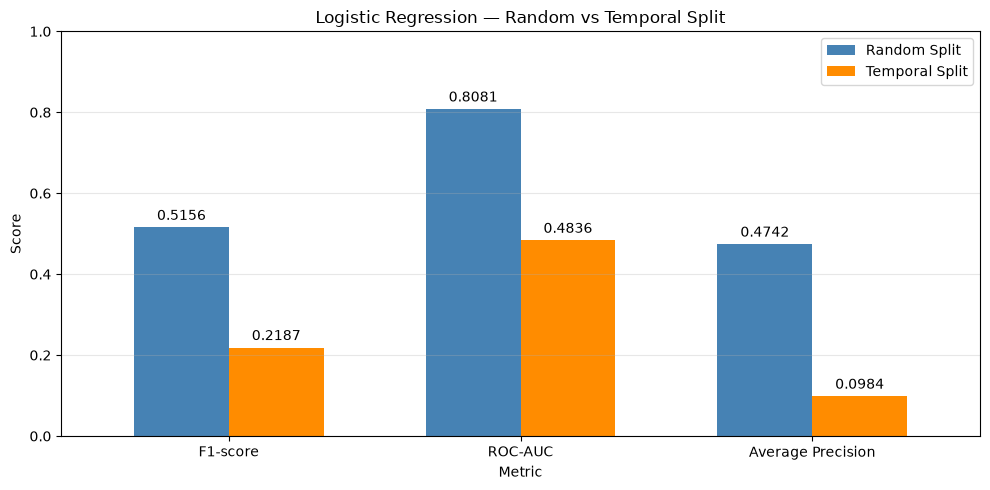

In [32]:
# Select the optimized Logistic Regression results
selected_metrics = [
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

plot_data = pd.DataFrame({
    "Random Split": [
        random_comparison.iloc[2][metric]
        for metric in selected_metrics
    ],
    "Temporal Split": [
        temporal_results.iloc[2][metric]
        for metric in selected_metrics
    ]
}, index=selected_metrics)

# Plot comparison
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
    width=0.65
)

plt.title("Logistic Regression — Random vs Temporal Split")
plt.ylabel("Score")
plt.xlabel("Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

### Temporal Sensitivity Analysis — Conclusion

The temporal split reveals a substantial decrease in
Logistic Regression performance compared with the
stratified random split.

#### Main findings

- ROC-AUC decreases from 0.8081 to 0.4836.
- Average Precision decreases from 0.4742 to 0.0984.
- Optimized F1-score decreases from 0.5156 to 0.2187.
- At the default threshold, no subscribers are identified.
- Threshold optimization improves recall to 81.47%,
  but precision remains low at 12.63%.
- The optimized temporal threshold is approximately
  7.7963e-06.

#### Interpretation

The temporal training set contains only 4.81% positive
observations, compared with 11.07% in the validation set.

This change in target distribution, together with potential
changes in macroeconomic variables and customer behavior,
may explain the deterioration in performance.

However, the individual impact of these factors has not
been experimentally verified.

The random split may provide an overly optimistic estimate
of performance when the model is intended to predict
future customer subscriptions.

Threshold optimization improves subscriber detection but
does not improve the model's discrimination ability.

#### Recommendations

- Investigate changes in macroeconomic feature distributions.
- Evaluate alternative models using temporal validation.
- Investigate class imbalance and probability calibration.
- Consider time-aware cross-validation.

#### Evaluation integrity

Both experiments use the same baseline models and
evaluation metrics. Preprocessing is fitted exclusively
on the corresponding training set.

Thresholds are selected independently on their respective
validation sets. The optimized validation scores may
therefore be optimistic.

Neither test set has been used for model evaluation
or threshold selection.

## Hyperparameter Tuning — Logistic Regression

The objective of this experiment is to improve the Logistic
Regression baseline through hyperparameter optimization
using GridSearchCV.

Two evaluation protocols are considered:

- Random stratified split.
- Chronological temporal split.

Hyperparameter selection is performed exclusively on training
data through cross-validation. Average Precision is used as
the optimization metric due to class imbalance.

The validation sets are used for performance evaluation and
decision threshold selection. The test sets remain untouched
throughout this experiment.

In [33]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    TimeSeriesSplit
)

### 1. Hyperparameter Tuning — Random Split

A 5-fold stratified cross-validation is used to select the
best Logistic Regression hyperparameters.

Stratification preserves the class distribution across folds.
Preprocessing is included inside the pipeline to prevent
data leakage during cross-validation.

Average Precision is used as the optimization metric
because the target variable is imbalanced.

In [34]:
# Create a new pipeline for hyperparameter tuning
logreg_tuning_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Define the hyperparameter grid
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear", "lbfgs"]
}

# Define stratified cross-validation
random_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [35]:
grid_search_random = GridSearchCV(
    estimator=logreg_tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=random_cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    error_score="raise"
)

# Fit exclusively on random training data
grid_search_random.fit(X_train, y_train)

# Display the best results
print("Best hyperparameters:")
print(grid_search_random.best_params_)

print("\nBest cross-validation Average Precision:")
print(f"{grid_search_random.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best hyperparameters:
{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Best cross-validation Average Precision:
0.4499


In [36]:
grid_search_random = GridSearchCV(
    estimator=logreg_tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=random_cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    error_score="raise"
)

# Fit exclusively on random training data
grid_search_random.fit(X_train, y_train)

# Display the best results
print("Best hyperparameters:")
print(grid_search_random.best_params_)

print("\nBest cross-validation Average Precision:")
print(f"{grid_search_random.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best hyperparameters:
{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Best cross-validation Average Precision:
0.4499


### 2. Tuned Logistic Regression — Random Validation

The best hyperparameters selected by GridSearchCV are:

- C = 1
- class_weight = None
- solver = liblinear

The best mean cross-validation Average Precision is 0.4499.

The selected model is now evaluated on the independent
random validation set using the default decision threshold
of 0.5. This allows a fair comparison with the untuned
Logistic Regression baseline.

In [37]:
# Retrieve the best fitted pipeline
best_logreg_random = grid_search_random.best_estimator_

# Verify positive class ordering
assert np.array_equal(best_logreg_random.classes_, [0, 1])

# Validation predictions and probabilities
y_pred_tuned_random = best_logreg_random.predict(X_val)
y_proba_tuned_random = best_logreg_random.predict_proba(X_val)[:, 1]

# Evaluate the tuned model
tuned_random_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_pred_tuned_random),
    "Precision": precision_score(
        y_val, y_pred_tuned_random, zero_division=0
    ),
    "Recall": recall_score(y_val, y_pred_tuned_random),
    "F1-score": f1_score(y_val, y_pred_tuned_random),
    "ROC-AUC": roc_auc_score(y_val, y_proba_tuned_random),
    "Average Precision": average_precision_score(
        y_val, y_proba_tuned_random
    )
}

pd.DataFrame([tuned_random_results]).round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned Logistic Regression,0.9012,0.6939,0.2198,0.3339,0.8082,0.4741


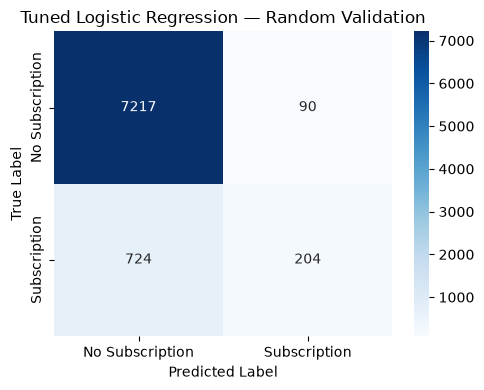

In [38]:
cm_tuned_random = confusion_matrix(y_val, y_pred_tuned_random)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tuned_random,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Tuned Logistic Regression — Random Validation")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 3. Threshold Optimization — Tuned Random Baseline

Although hyperparameter tuning produces nearly identical
performance to the original Logistic Regression baseline,
the default threshold of 0.5 still results in low recall.

The decision threshold is optimized independently for the
tuned model by maximizing the F1-score on the validation set.

No test data is used for threshold selection.

In [39]:
# Compute precision and recall for different thresholds
precision_tuned_random, recall_tuned_random, thresholds_tuned_random = (
    precision_recall_curve(y_val, y_proba_tuned_random)
)

# Compute F1-score for each threshold
f1_tuned_random = np.divide(
    2 * precision_tuned_random[:-1] * recall_tuned_random[:-1],
    precision_tuned_random[:-1] + recall_tuned_random[:-1],
    out=np.zeros_like(thresholds_tuned_random),
    where=(
        precision_tuned_random[:-1] + recall_tuned_random[:-1]
    ) != 0
)

# Select the threshold maximizing validation F1-score
best_idx_tuned_random = np.argmax(f1_tuned_random)

best_threshold_tuned_random = thresholds_tuned_random[
    best_idx_tuned_random
]

print("Optimal threshold:", best_threshold_tuned_random)

print(
    "Best validation F1-score:",
    round(f1_tuned_random[best_idx_tuned_random], 4)
)

Optimal threshold: 0.23756088960591715
Best validation F1-score: 0.5147


In [40]:
# Apply the optimized threshold
y_pred_tuned_random_opt = (
    y_proba_tuned_random >= best_threshold_tuned_random
).astype(int)

# Evaluate optimized predictions
tuned_random_opt_results = {
    "Model": "Tuned Logistic Regression (Optimized Threshold)",
    "Accuracy": accuracy_score(y_val, y_pred_tuned_random_opt),
    "Precision": precision_score(
        y_val, y_pred_tuned_random_opt, zero_division=0
    ),
    "Recall": recall_score(y_val, y_pred_tuned_random_opt),
    "F1-score": f1_score(y_val, y_pred_tuned_random_opt),
    "ROC-AUC": roc_auc_score(y_val, y_proba_tuned_random),
    "Average Precision": average_precision_score(
        y_val, y_proba_tuned_random
    )
}

pd.DataFrame([
    tuned_random_results,
    tuned_random_opt_results
]).round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned Logistic Regression,0.9012,0.6939,0.2198,0.3339,0.8082,0.4741
1,Tuned Logistic Regression (Optimized Threshold),0.8880,0.5031,0.5269,0.5147,0.8082,0.4741


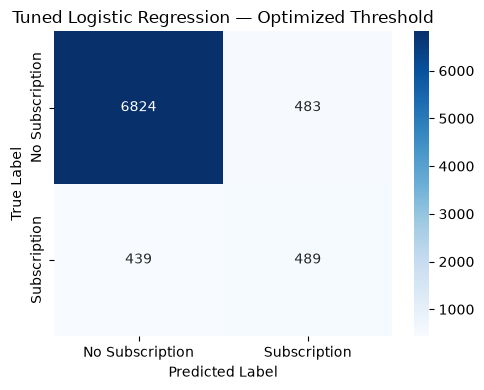

In [41]:
cm_tuned_random_opt = confusion_matrix(
    y_val, y_pred_tuned_random_opt
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tuned_random_opt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Tuned Logistic Regression — Optimized Threshold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 4. Hyperparameter Tuning — Temporal Split

The Logistic Regression hyperparameters are optimized
independently using the temporal training set.

TimeSeriesSplit with five folds is used to preserve
chronological order and prevent training on future
observations when validating on earlier observations.

The same hyperparameter grid and Average Precision
optimization metric are used for consistency with
the random split experiment.

The external validation and test sets are excluded
from hyperparameter selection.

In [42]:
# Define chronological cross-validation
temporal_cv = TimeSeriesSplit(n_splits=5)

# Verify the chronological folds
for fold, (train_idx, val_idx) in enumerate(
    temporal_cv.split(X_train_time), start=1
):
    assert train_idx.max() < val_idx.min()

    # Verify that both classes are present
    assert y_train_time.iloc[train_idx].nunique() == 2
    assert y_train_time.iloc[val_idx].nunique() == 2

    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}, "
        f"Train positive rate = "
        f"{y_train_time.iloc[train_idx].mean():.2%}, "
        f"Validation positive rate = "
        f"{y_train_time.iloc[val_idx].mean():.2%}"
    )

Fold 1: Train = 4120, Validation = 4117, Train positive rate = 2.77%, Validation positive rate = 3.52%
Fold 2: Train = 8237, Validation = 4117, Train positive rate = 3.14%, Validation positive rate = 4.23%
Fold 3: Train = 12354, Validation = 4117, Train positive rate = 3.50%, Validation positive rate = 6.63%
Fold 4: Train = 16471, Validation = 4117, Train positive rate = 4.29%, Validation positive rate = 6.24%
Fold 5: Train = 20588, Validation = 4117, Train positive rate = 4.68%, Validation positive rate = 5.47%


In [43]:
# Create a separate temporal pipeline
logreg_temporal_tuning_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Configure GridSearchCV
grid_search_temporal = GridSearchCV(
    estimator=logreg_temporal_tuning_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    error_score="raise"
)

# Fit exclusively on temporal training data
grid_search_temporal.fit(X_train_time, y_train_time)

print("Best temporal hyperparameters:")
print(grid_search_temporal.best_params_)

print("\nBest temporal CV Average Precision:")
print(f"{grid_search_temporal.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best temporal hyperparameters:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Best temporal CV Average Precision:
0.0557


### 5. Tuned Logistic Regression — Temporal Validation

The best hyperparameters selected by temporal GridSearchCV are:

- C = 0.1
- class_weight = None
- solver = liblinear

The best mean cross-validation Average Precision is 0.0557.

Compared with the random split, the temporal protocol
selects stronger regularization.

The selected model is evaluated on the independent temporal
validation set using the default decision threshold of 0.5.

The test set remains excluded from the experiment.

In [44]:
# Retrieve the best fitted temporal pipeline
best_logreg_temporal = grid_search_temporal.best_estimator_

# Verify positive class ordering
assert np.array_equal(best_logreg_temporal.classes_, [0, 1])

# Temporal validation predictions and probabilities
y_pred_tuned_temporal = best_logreg_temporal.predict(X_val_time)

y_proba_tuned_temporal = best_logreg_temporal.predict_proba(
    X_val_time
)[:, 1]

# Evaluate the tuned temporal model
tuned_temporal_results = {
    "Model": "Tuned Logistic Regression (Temporal)",
    "Accuracy": accuracy_score(
        y_val_time, y_pred_tuned_temporal
    ),
    "Precision": precision_score(
        y_val_time, y_pred_tuned_temporal, zero_division=0
    ),
    "Recall": recall_score(
        y_val_time, y_pred_tuned_temporal, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_time, y_pred_tuned_temporal, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_time, y_proba_tuned_temporal
    ),
    "Average Precision": average_precision_score(
        y_val_time, y_proba_tuned_temporal
    )
}

pd.DataFrame([tuned_temporal_results]).round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned Logistic Regression (Temporal),0.8893,0.0,0.0,0.0,0.4841,0.0985


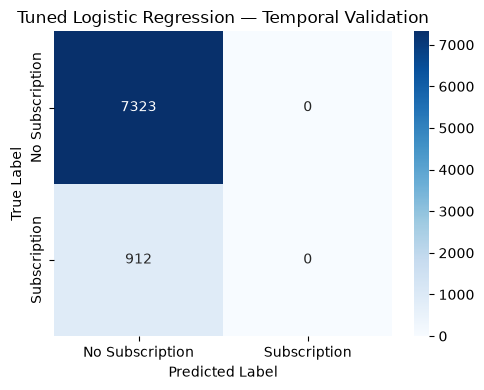

In [45]:
cm_tuned_temporal = confusion_matrix(
    y_val_time, y_pred_tuned_temporal
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tuned_temporal,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Tuned Logistic Regression — Temporal Validation")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 6. Threshold Optimization — Tuned Temporal Baseline

The tuned temporal Logistic Regression predicts all
observations as negative at the default threshold of 0.5.

The classification threshold is therefore optimized
independently on the temporal validation set by maximizing
the F1-score.

This experiment investigates whether threshold adjustment
can improve minority-class detection despite the weak
temporal discrimination performance.

The test set is not used for threshold selection.

In [47]:
# Compute precision and recall for different thresholds
precision_tuned_temporal, recall_tuned_temporal, thresholds_tuned_temporal = (
    precision_recall_curve(
        y_val_time, y_proba_tuned_temporal
    )
)

# Compute F1-score for each threshold
f1_tuned_temporal = np.divide(
    2 * precision_tuned_temporal[:-1] * recall_tuned_temporal[:-1],
    precision_tuned_temporal[:-1] + recall_tuned_temporal[:-1],
    out=np.zeros_like(thresholds_tuned_temporal),
    where=(
        precision_tuned_temporal[:-1] +
        recall_tuned_temporal[:-1]
    ) != 0
)

# Select the threshold maximizing validation F1-score
best_idx_tuned_temporal = np.argmax(f1_tuned_temporal)

best_threshold_tuned_temporal = thresholds_tuned_temporal[
    best_idx_tuned_temporal
]

print("Optimal temporal threshold:", best_threshold_tuned_temporal)

print(
    "Best validation F1-score:",
    round(f1_tuned_temporal[best_idx_tuned_temporal], 4)
)

Optimal temporal threshold: 1.28981010824029e-05
Best validation F1-score: 0.2195


In [48]:
# Apply the optimized threshold
y_pred_tuned_temporal_opt = (
    y_proba_tuned_temporal >= best_threshold_tuned_temporal
).astype(int)

# Evaluate optimized predictions
tuned_temporal_opt_results = {
    "Model": "Tuned Temporal LR (Optimized Threshold)",
    "Accuracy": accuracy_score(
        y_val_time, y_pred_tuned_temporal_opt
    ),
    "Precision": precision_score(
        y_val_time, y_pred_tuned_temporal_opt, zero_division=0
    ),
    "Recall": recall_score(
        y_val_time, y_pred_tuned_temporal_opt, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_time, y_pred_tuned_temporal_opt, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_time, y_proba_tuned_temporal
    ),
    "Average Precision": average_precision_score(
        y_val_time, y_proba_tuned_temporal
    )
}

pd.DataFrame([
    tuned_temporal_results,
    tuned_temporal_opt_results
]).round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned Logistic Regression (Temporal),0.8893,0.0000,0.0000,0.0000,0.4841,0.0985
1,Tuned Temporal LR (Optimized Threshold),0.3791,0.1275,0.7884,0.2195,0.4841,0.0985


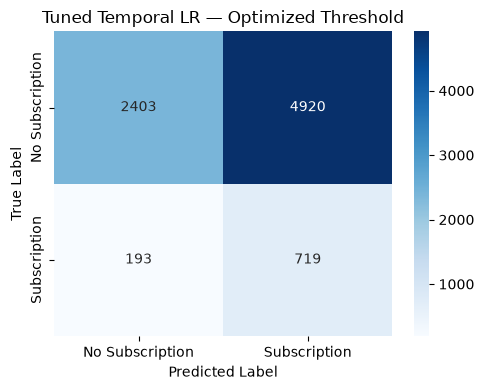

In [49]:
cm_tuned_temporal_opt = confusion_matrix(
    y_val_time, y_pred_tuned_temporal_opt
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tuned_temporal_opt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Tuned Temporal LR — Optimized Threshold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 7. Final Comparison — Tuned and Untuned Baselines

This section compares the original and tuned Logistic
Regression models under both random and temporal protocols.

All models are compared using their independently optimized
validation thresholds.

The objective is to assess whether hyperparameter tuning
improves predictive performance and temporal generalization.

All reported results are obtained on validation data.

In [50]:
final_baseline_comparison = pd.DataFrame([
    {
        "Protocol": "Random",
        "Model": "Untuned Logistic Regression",
        "Threshold": 0.2385,
        "Accuracy": 0.8884,
        "Precision": 0.5046,
        "Recall": 0.5269,
        "F1-score": 0.5156,
        "ROC-AUC": 0.8081,
        "Average Precision": 0.4742
    },
    {
        **tuned_random_opt_results,
        "Protocol": "Random",
        "Model": "Tuned Logistic Regression",
        "Threshold": best_threshold_tuned_random
    },
    {
        "Protocol": "Temporal",
        "Model": "Untuned Logistic Regression",
        "Threshold": 7.796304746164699e-06,
        "Accuracy": 0.3552,
        "Precision": 0.1263,
        "Recall": 0.8147,
        "F1-score": 0.2187,
        "ROC-AUC": 0.4836,
        "Average Precision": 0.0984
    },
    {
        **tuned_temporal_opt_results,
        "Protocol": "Temporal",
        "Model": "Tuned Logistic Regression",
        "Threshold": best_threshold_tuned_temporal
    }
])

final_baseline_comparison = final_baseline_comparison[
    [
        "Protocol",
        "Model",
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ]
]

final_baseline_comparison.round(8)

,Protocol,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Random,Untuned Logistic Regression,0.238500,0.888400,0.504600,0.526900,0.515600,0.808100,0.474200
1,Random,Tuned Logistic Regression,0.237561,0.888039,0.503086,0.526940,0.514737,0.808185,0.474091
2,Temporal,Untuned Logistic Regression,0.000008,0.355200,0.126300,0.814700,0.218700,0.483600,0.098400
3,Temporal,Tuned Logistic Regression,0.000013,0.379114,0.127505,0.788377,0.219508,0.484146,0.098533


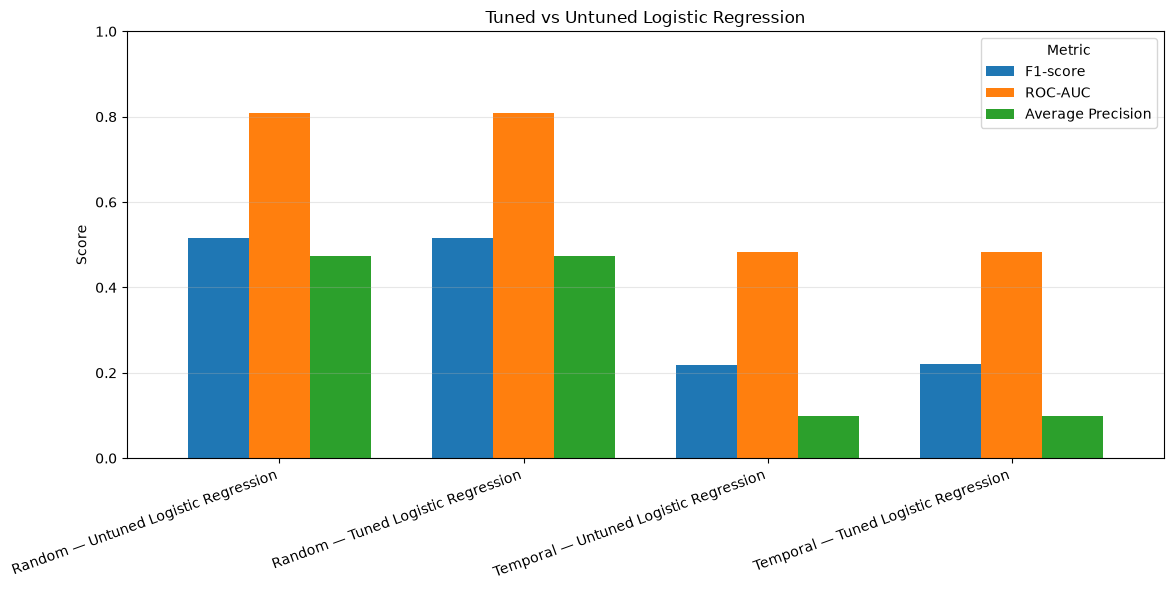

In [51]:
metrics_to_compare = [
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

plot_data = final_baseline_comparison.copy()

plot_data["Experiment"] = (
    plot_data["Protocol"] + " — " + plot_data["Model"]
)

plot_data.set_index("Experiment")[
    metrics_to_compare
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Tuned vs Untuned Logistic Regression")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Conclusion — Hyperparameter Tuning

GridSearchCV was applied to Logistic Regression under
both random and temporal evaluation protocols.

#### Random Split

The best configuration was C=1, class_weight=None,
and solver=liblinear, with a mean cross-validation
Average Precision of 0.4499.

After threshold optimization, the tuned model achieved:

- F1-score: 0.5147
- ROC-AUC: 0.8082
- Average Precision: 0.4741
- Recall: 0.5269

The results are nearly identical to the untuned baseline.
Hyperparameter tuning did not provide a meaningful
performance improvement.

#### Temporal Split

The best configuration was C=0.1, class_weight=None,
and solver=liblinear, with a mean cross-validation
Average Precision of 0.0557.

After threshold optimization, the tuned model achieved:

- F1-score: 0.2195
- ROC-AUC: 0.4841
- Average Precision: 0.0985
- Recall: 0.7884
- Precision: 0.1275

Stronger regularization did not overcome the poor
temporal generalization performance.

Although threshold optimization improved recall,
the model generated 4,920 false positives and retained
weak discrimination performance.

#### Main Findings

- Hyperparameter tuning provides negligible improvement
  under both evaluation protocols.
- Temporal evaluation reveals substantially weaker
  generalization than random evaluation.
- The positive class rate changes from 4.81% in temporal
  training to 11.07% in temporal validation.
- Changes in macroeconomic conditions may contribute
  to the performance degradation, but further drift
  analysis is required to investigate this explanation.
- Threshold optimization improves minority-class
  detection but does not improve discrimination.

#### Methodological Limitations

- Average Precision is sensitive to class prevalence.
- Validation F1-scores may be optimistic because the
  same validation data was used for threshold selection.
- Random splitting may produce optimistic estimates
  due to repeated feature patterns and temporal dependence.
- The temporal protocol assumes that the cleaned dataset
  preserves the original chronological ordering.

#### Experimental Integrity

Preprocessing was fitted inside each cross-validation
training fold.

StratifiedKFold was used for random cross-validation,
while TimeSeriesSplit was used for temporal cross-validation.

Hyperparameters were selected exclusively on training data.
Decision thresholds were selected independently on the
corresponding validation sets.

No test data was used during these baseline experiments.

### Appendix — AI Governance Verification

This section verifies the splitting logic proposed in
the initial AI response against the shared project
implementation.

The objective is to ensure experimental consistency
across team members without accessing the held-out
test sets.

In [52]:
from sklearn.model_selection import train_test_split
from src.data_prep import split, time_split

audit_df = pd.read_csv("bank_clean.csv")

X_audit = audit_df.drop(columns=["y"])
y_audit = audit_df["y"]

# Initial AI-proposed random split
X_train_ai, X_temp_ai, y_train_ai, y_temp_ai = train_test_split(
    X_audit,
    y_audit,
    test_size=0.40,
    stratify=y_audit,
    random_state=42
)

X_val_ai, _, y_val_ai, _ = train_test_split(
    X_temp_ai,
    y_temp_ai,
    test_size=0.50,
    stratify=y_temp_ai,
    random_state=42
)

# Shared random split
X_train_shared, X_val_shared, _, y_train_shared, y_val_shared, _ = split(audit_df)

# Initial AI-proposed temporal split
n = len(audit_df)

X_train_time_ai = X_audit.iloc[:int(0.60 * n)]
X_val_time_ai = X_audit.iloc[int(0.60 * n):int(0.80 * n)]

# Shared temporal split
X_train_time_shared, X_val_time_shared, _, _, _, _ = time_split(audit_df)

# Compare row indices
split_audit = pd.DataFrame([
    {
        "Protocol": "Random",
        "Identical training indices": X_train_ai.index.equals(
            X_train_shared.index
        ),
        "Identical validation indices": X_val_ai.index.equals(
            X_val_shared.index
        )
    },
    {
        "Protocol": "Temporal",
        "Identical training indices": X_train_time_ai.index.equals(
            X_train_time_shared.index
        ),
        "Identical validation indices": X_val_time_ai.index.equals(
            X_val_time_shared.index
        )
    }
])

display(split_audit)

,Protocol,Identical training indices,Identical validation indices
0,Random,True,True
1,Temporal,True,True


#### Split Consistency Audit — Results

The random and temporal training and validation indices
generated by the initial AI response were identical to
those produced by the shared project functions.

All four index comparison checks returned True.

Therefore, no experimental inconsistency was detected.

Nevertheless, the shared split() and time_split()
functions were retained to ensure reproducibility,
maintainability and consistency across team members.

This finding represents a potential maintenance risk,
not a confirmed data leakage or splitting error.

In [53]:
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit

cv_audit_records = []

for name, cv in [
    (
        "StratifiedKFold",
        StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )
    ),
    ("TimeSeriesSplit", TimeSeriesSplit(n_splits=5))
]:
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train_time, y_train_time),
        start=1
    ):
        cv_audit_records.append({
            "CV Strategy": name,
            "Fold": fold,
            "Last training position": train_idx.max(),
            "First validation position": val_idx.min(),
            "Chronological order respected": (
                train_idx.max() < val_idx.min()
            )
        })

cv_audit_df = pd.DataFrame(cv_audit_records)

display(cv_audit_df)

,CV Strategy,Fold,Last training position,First validation position,Chronological order respected
0,StratifiedKFold,1,24704,6,False
1,StratifiedKFold,2,24704,2,False
2,StratifiedKFold,3,24704,0,False
3,StratifiedKFold,4,24703,4,False
4,StratifiedKFold,5,24704,1,False
5,TimeSeriesSplit,1,4119,4120,True
6,TimeSeriesSplit,2,8236,8237,True
7,TimeSeriesSplit,3,12353,12354,True
8,TimeSeriesSplit,4,16470,16471,True
9,TimeSeriesSplit,5,20587,20588,True


#### Cross-Validation Strategy Audit — Results

The chronological ordering verification produced
the following results:

- StratifiedKFold: 0 out of 5 folds respected
  chronological ordering.
- TimeSeriesSplit: 5 out of 5 folds respected
  chronological ordering.

These results justify the use of TimeSeriesSplit
for temporal hyperparameter optimization.

StratifiedKFold remains appropriate for the random
evaluation protocol, subject to its independence
assumptions.

The initial AI response correctly recommended
TimeSeriesSplit. This verification therefore confirms
a methodological recommendation rather than correcting
an observed AI error.

The verification assumes that the dataset preserves
its original chronological row ordering.